In [28]:
#Alzheimer's vs healthy EEG

In [29]:
!pip install -q openneuro-py mne

import os, glob, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import openneuro as on
from scipy.signal import welch, coherence
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, LeaveOneGroupOut,
                                     GridSearchCV, cross_val_score, cross_validate, cross_val_predict)
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
results = {}

In [30]:
on.download(dataset="ds004504", target_dir="ds004504", include=["participants.tsv"])
df = pd.read_csv("ds004504/participants.tsv", sep="\t")
print(df["Group"].value_counts())   # A: 36, C: 29, F: 23

# download the cleaned EEG of all 88 people
on.download(dataset="ds004504", target_dir="ds004504",
            include=[f"derivatives/{s}" for s in df["participant_id"]])

Overall ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 3.0/3.0 GB 193.7 MB/s 0:00:00

✅ Finished downloading ds004504 (downloaded 0 files and 0 B).


In [31]:
SFREQ = 250                 # samples per second
EPOCH_SEC = 20              # length of each piece we cut
NPERSEG = 4 * SFREQ         # welch window = 4 seconds
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}   # wave types in Hz
REGIONS = {                 # 19 electrodes grouped into 5 brain areas
    "frontal":   ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8"],
    "central":   ["C3", "Cz", "C4"],
    "temporal":  ["T3", "T4", "T5", "T6"],
    "parietal":  ["P3", "Pz", "P4"],
    "occipital": ["O1", "O2"],
}
PAIRS = list(itertools.combinations(REGIONS.keys(), 2))   # all 10 region pairs (for coherence)
FREQS = np.fft.rfftfreq(NPERSEG, 1 / SFREQ)               # frequencies welch will give
TOTAL = (FREQS >= 0.5) & (FREQS < 45)                     # range we care about
FREQ_USED = FREQS[TOTAL]

In [32]:
def load_clean(path):
    # read one person's EEG and prepare it
    raw = mne.io.read_raw_eeglab(path, preload=True)
    raw.filter(0.5, 45.0)       # remove slow drift and fast noise
    raw.resample(SFREQ)         # same speed for everyone
    return raw.get_data(), [n.lower() for n in raw.ch_names]


def features_for_epoch(ep, names):
    # turns ONE 20 s piece into 33 numbers for the model
    freqs, psd = welch(ep, fs=SFREQ, nperseg=NPERSEG)
    f, region_signal = {}, {}

    # relative band power per region (20 numbers)
    for region, chans in REGIONS.items():
        rows = [names.index(c.lower()) for c in chans]
        p = psd[rows].mean(axis=0)
        region_signal[region] = ep[rows].mean(axis=0)
        for band, (lo, hi) in BANDS.items():
            m = (freqs >= lo) & (freqs < hi)
            f[f"{region}_{band}"] = p[m].sum() / p[TOTAL].sum()

    # slowing ratios (higher = slower brain waves) (2 numbers)
    f["theta_alpha_ratio"] = np.mean([f[f"{r}_theta"] / f[f"{r}_alpha"] for r in REGIONS])
    f["slowing_ratio"] = np.mean([(f[f"{r}_delta"] + f[f"{r}_theta"]) /
                                  (f[f"{r}_alpha"] + f[f"{r}_beta"]) for r in REGIONS])

    # alpha peak frequency at the back of the head (1 number)
    back = [names.index(c.lower()) for c in REGIONS["parietal"] + REGIONS["occipital"]]
    p_back = psd[back].mean(axis=0)
    ar = (freqs >= 6) & (freqs <= 13)
    f["alpha_peak_freq"] = freqs[ar][np.argmax(p_back[ar])]

    # alpha coherence between region pairs (10 numbers)
    for a, b in PAIRS:
        fc, coh = coherence(region_signal[a], region_signal[b], fs=SFREQ, nperseg=NPERSEG)
        f[f"coh_alpha_{a}_{b}"] = coh[(fc >= 8) & (fc < 13)].mean()

    spec = psd.mean(axis=0)[TOTAL]          # average spectrum, only for the plot later
    return f, spec / spec.sum()

In [33]:
CACHE_FEAT, CACHE_SPEC = "epoch_features.csv", "spectra.npz"

# if we already did this once, just load the saved result
if os.path.exists(CACHE_FEAT) and os.path.exists(CACHE_SPEC):
    epoch_df = pd.read_csv(CACHE_FEAT)
    spectra = np.load(CACHE_SPEC)["spectra"]
else:
    rows, spectra = [], []
    step = EPOCH_SEC * SFREQ
    for _, r in df.iterrows():                       # go through every person
        sid = r["participant_id"]
        path = glob.glob(f"ds004504/derivatives/{sid}/eeg/*.set")[0]
        data, names = load_clean(path)
        specs = []
        for i in range(data.shape[1] // step):       # go through every 20 s piece
            ep = data[:, i * step:(i + 1) * step]
            f, spec = features_for_epoch(ep, names)
            f["subject"], f["epoch"] = sid, i

            rows.append(f)
            specs.append(spec)
        spectra.append(np.mean(specs, axis=0))
        print(sid, len(specs), "epochs")
    epoch_df = pd.DataFrame(rows)
    spectra = np.array(spectra)
    epoch_df.to_csv(CACHE_FEAT, index=False)         # save so we never have to redo this
    np.savez(CACHE_SPEC, spectra=spectra)

FEATURES = [c for c in epoch_df.columns if c not in ("subject", "epoch", "quality")]
# one row per person = average of all their pieces
subj_df = epoch_df.groupby("subject")[FEATURES].mean().loc[df["participant_id"]]
group = df["Group"].values
print(epoch_df.shape, subj_df.shape, "->", len(FEATURES), "features")

(3446, 36) (88, 33) -> 33 features


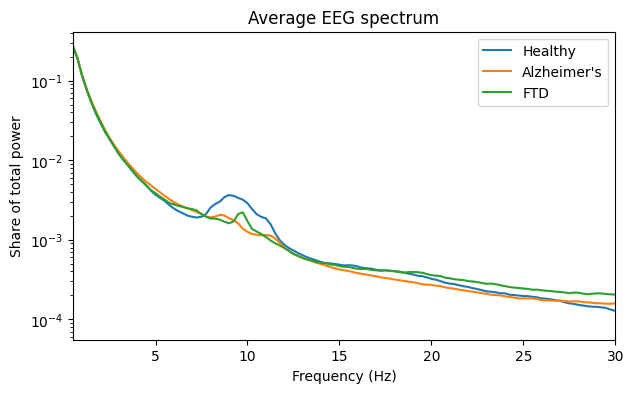

In [34]:
# how much power each group has at each frequency
plt.figure(figsize=(7, 4))
for g, label in [("C", "Healthy"), ("A", "Alzheimer's"), ("F", "FTD")]:
    plt.plot(FREQ_USED, spectra[group == g].mean(axis=0), label=label)
plt.xlim(0.5, 30); plt.yscale("log")      # log scale shows small differences better
plt.xlabel("Frequency (Hz)"); plt.ylabel("Share of total power"); plt.title("Average EEG spectrum")
plt.legend(); plt.savefig("alz_spectrum.png", dpi=150, bbox_inches="tight"); plt.show()

In [35]:
# keep only Alzheimer's (1) vs healthy (0) for the main tests
mask = np.isin(group, ["A", "C"])
dfx = df[mask].reset_index(drop=True)
X = subj_df[mask]
y = (dfx["Group"] == "A").astype(int).values

# is one group much older? (a model could just learn age)
print(dfx.groupby("Group")["Age"].agg(["mean", "std"]).round(1))
print("Age difference p-value:", round(mannwhitneyu(dfx.loc[y == 1, "Age"], dfx.loc[y == 0, "Age"]).pvalue, 3))


def bh_fdr(p):
    # correction for testing many features at once (avoids false "significant" results)
    p = np.asarray(p); n = len(p); order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1)
    return out


# test every feature: is it different between the two groups?
rows = []
for c in FEATURES:
    a, h = X.loc[y == 1, c], X.loc[y == 0, c]
    rows.append((c, h.median(), a.median(), mannwhitneyu(a, h).pvalue))
stats = pd.DataFrame(rows, columns=["feature", "healthy_median", "alz_median", "p"])
stats["p_fdr"] = bh_fdr(stats["p"])
stats = stats.sort_values("p").reset_index(drop=True)
print(stats.head(10).round(4))
print("Significant after correction (q < 0.05):", int((stats["p_fdr"] < 0.05).sum()))
results["n_significant_features"] = int((stats["p_fdr"] < 0.05).sum())

       mean  std
Group           
A      66.4  7.9
C      67.9  5.4
Age difference p-value: 0.383
                        feature  healthy_median  alz_median       p   p_fdr
0               occipital_alpha          0.0833      0.0251  0.0000  0.0001
1               alpha_peak_freq          8.9148      6.6663  0.0000  0.0001
2             theta_alpha_ratio          1.6471      2.9252  0.0000  0.0002
3                 frontal_theta          0.0474      0.0558  0.0000  0.0003
4  coh_alpha_parietal_occipital          0.7927      0.8801  0.0000  0.0003
5   coh_alpha_central_occipital          0.3817      0.5321  0.0001  0.0008
6               occipital_delta          0.8354      0.8896  0.0002  0.0010
7                temporal_alpha          0.0515      0.0221  0.0003  0.0010
8                parietal_alpha          0.0351      0.0186  0.0003  0.0010
9                temporal_theta          0.0481      0.0557  0.0003  0.0010
Significant after correction (q < 0.05): 23


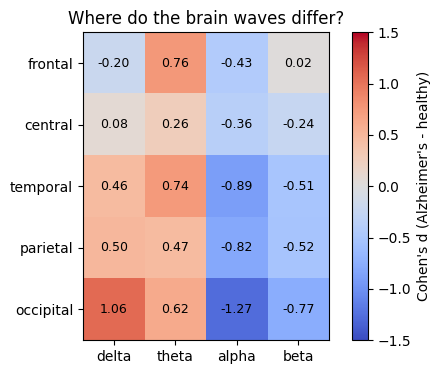

In [36]:
# effect size (Cohen's d) per brain area and wave type: red = higher in Alzheimer's, blue = lower
regs, bands = list(REGIONS), list(BANDS)
d = np.zeros((len(regs), len(bands)))
for i, r in enumerate(regs):
    for j, b in enumerate(bands):
        a, h = X.loc[y == 1, f"{r}_{b}"], X.loc[y == 0, f"{r}_{b}"]
        d[i, j] = (a.mean() - h.mean()) / np.sqrt((a.var() + h.var()) / 2)

plt.figure(figsize=(6, 4))
plt.imshow(d, cmap="coolwarm", vmin=-1.5, vmax=1.5)
plt.xticks(range(len(bands)), bands); plt.yticks(range(len(regs)), regs)
for i in range(len(regs)):
    for j in range(len(bands)):
        plt.text(j, i, f"{d[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(label="Cohen's d (Alzheimer's - healthy)")
plt.title("Where do the brain waves differ?")
plt.savefig("alz_effect_size.png", dpi=150, bbox_inches="tight"); plt.show()

In [37]:
# 5-fold CV repeated 10 times; each test is on people the model never saw
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
models = {
    "Always bigger group": DummyClassifier(strategy="most_frequent"),   # reference: just guesses
    "Logistic regression": LogisticRegression(C=0.1, max_iter=5000),
    "SVM": SVC(C=1.0),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=3, random_state=0),
}
for name, m in models.items():
    r = cross_validate(make_pipeline(StandardScaler(), m), X, y, cv=cv, scoring=["accuracy", "roc_auc"])
    auc = r["test_roc_auc"].mean() if name != "Always bigger group" else 0.5
    print(f"{name:22s} accuracy {r['test_accuracy'].mean():.3f} (+/- {r['test_accuracy'].std():.3f})   AUC {auc:.3f}")
    results[name] = round(r["test_accuracy"].mean(), 3)

# reference: a model that only knows age
r = cross_validate(make_pipeline(StandardScaler(), LogisticRegression()), dfx[["Age"]], y, cv=cv, scoring="accuracy")
print(f"{'Age only':22s} accuracy {r['test_score'].mean():.3f}")
results["Age only"] = round(r["test_score"].mean(), 3)

Always bigger group    accuracy 0.554 (+/- 0.031)   AUC 0.500
Logistic regression    accuracy 0.795 (+/- 0.109)   AUC 0.863
SVM                    accuracy 0.752 (+/- 0.131)   AUC 0.847
Random forest          accuracy 0.731 (+/- 0.116)   AUC 0.838
Age only               accuracy 0.508


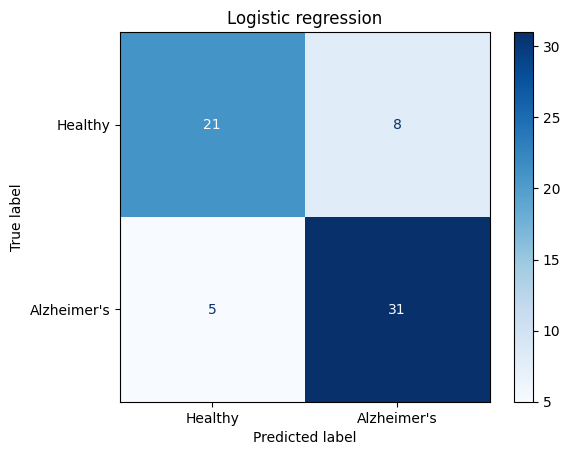

In [38]:
# shows how many people of each group were predicted right or mixed up
best = "Logistic regression"   # change this if another model scored best
pred = cross_val_predict(make_pipeline(StandardScaler(), models[best]), X, y,
                         cv=StratifiedKFold(5, shuffle=True, random_state=0))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Healthy", "Alzheimer's"], cmap="Blues")
plt.title(best); plt.savefig("alz_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

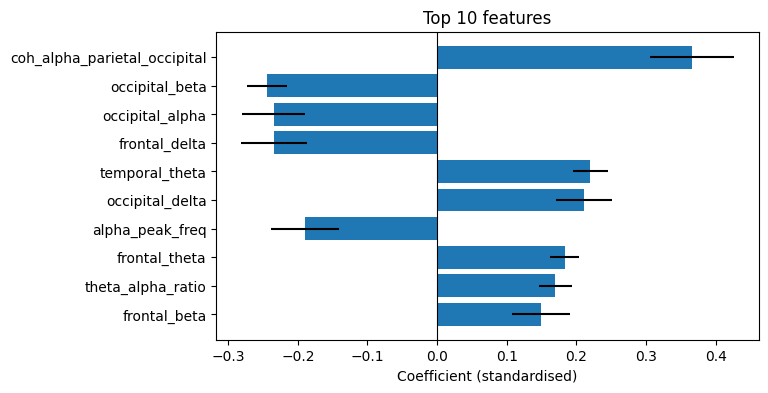

theta_alpha_ratio  vs MMSE in Alzheimer's group: rho = -0.21, p = 0.214
slowing_ratio      vs MMSE in Alzheimer's group: rho = -0.27, p = 0.110
alpha_peak_freq    vs MMSE in Alzheimer's group: rho = 0.22, p = 0.204


In [26]:
# average the model's coefficients over many folds (positive = pushes towards Alzheimer's)
coefs = []
for tr, _ in RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0).split(X, y):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)).fit(X.iloc[tr], y[tr])
    coefs.append(m[-1].coef_[0])
coefs = np.array(coefs)
imp = pd.DataFrame({"feature": FEATURES, "mean": coefs.mean(0), "std": coefs.std(0)})
top = imp.reindex(imp["mean"].abs().sort_values(ascending=False).index).head(10)[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["mean"], xerr=top["std"])    # bars = importance, lines = how much it varies
plt.axvline(0, color="k", lw=0.8); plt.xlabel("Coefficient (standardised)")
plt.title("Top 10 features"); plt.savefig("alz_importance.png", dpi=150, bbox_inches="tight"); plt.show()

# do EEG features follow disease severity? (MMSE: lower = more impaired)
ad = (dfx["Group"] == "A").values
for c in ["theta_alpha_ratio", "slowing_ratio", "alpha_peak_freq"]:
    rho, p = spearmanr(X.loc[ad, c], dfx.loc[ad, "MMSE"])
    print(f"{c:18s} vs MMSE in Alzheimer's group: rho = {rho:.2f}, p = {p:.3f}")

Logistic regression    accuracy 0.577 | balanced accuracy 0.524
Random forest          accuracy 0.518 | balanced accuracy 0.474


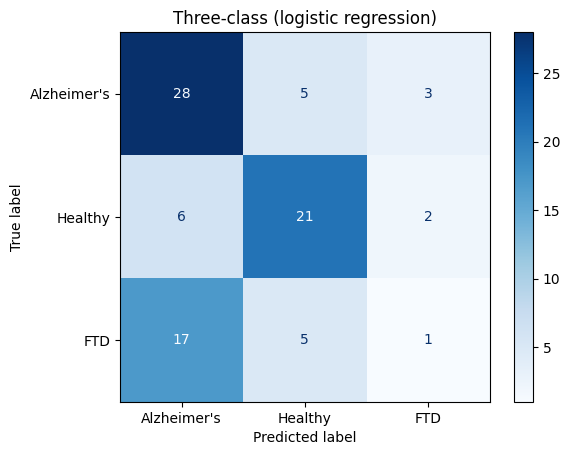

In [27]:
y3 = group
cv3 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
for name, m in {"Logistic regression": LogisticRegression(C=0.1, max_iter=5000),
                "Random forest": RandomForestClassifier(n_estimators=200, max_depth=3, random_state=0)}.items():
    r = cross_validate(make_pipeline(StandardScaler(), m), subj_df, y3, cv=cv3, scoring=["accuracy", "balanced_accuracy"])
    print(f"{name:22s} accuracy {r['test_accuracy'].mean():.3f} | balanced accuracy {r['test_balanced_accuracy'].mean():.3f}")
    results[f"{name} (3-class)"] = round(r["test_balanced_accuracy"].mean(), 3)

# confusion matrix for 3 groups
pred3 = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)), subj_df, y3,
                          cv=StratifiedKFold(5, shuffle=True, random_state=0))
ConfusionMatrixDisplay.from_predictions(y3, pred3, display_labels=["Alzheimer's", "Healthy", "FTD"],
                                        labels=["A", "C", "F"], cmap="Blues")
plt.title("Three-class (logistic regression)"); plt.savefig("alz_confusion_3class.png", dpi=150, bbox_inches="tight"); plt.show()